<a href="https://colab.research.google.com/github/CECS-AI/ai101-assignment4-prangara-vols-2/blob/main/Assignment4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Gemini: Connecting to Gemini

The Gemini API allows you to connect to Google's most powerful multi-modal model. This example configures your API key and sends an example message to the API and prints a response.

Before you start, visit https://aistudio.google.com/app/apikey to create an API key.

In [3]:
# Used hugging face (Qwen model) to obtain API key as it is free and users are allotted more tokens free per day compared to Gemini

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

!pip install huggingface_hub -q

# Import NumPy for numerical operations (arrays, math functions)
import numpy as np  

# Import Matplotlib's pyplot for plotting graphs
import matplotlib.pyplot as plt  

# Import Seaborn for more advanced and visually appealing statistical plots
import seaborn as sns  

# Import function to split dataset into training and testing sets
from sklearn.model_selection import train_test_split  

# Import Linear Regression model from scikit-learn
from sklearn.linear_model import LinearRegression  

# Import evaluation metrics: Mean Squared Error and R² score
from sklearn.metrics import mean_squared_error, r2_score  


# Install external Python packages:
# - huggingface_hub: allows access to Hugging Face models and APIs
# - -q: quiet mode, reduces installation output in the console
!pip install huggingface_hub -q

In [4]:
from huggingface_hub import InferenceClient
from google.colab import userdata
import pandas as pd
import matplotlib.pyplot as plt
import io

HF_TOKEN = userdata.get('HF_TOKEN')
MODEL_ID  = "Qwen/Qwen2.5-72B-Instruct"
client    = InferenceClient(model=MODEL_ID, token=HF_TOKEN)

def ask(prompt, max_new_tokens=600):
    response = client.chat_completion(
        messages=[{"role": "user", "content": prompt}],
        max_tokens=max_new_tokens,
        temperature=0.3,
    )
    return response.choices[0].message.content.strip()

print(ask("What is the capital of France? One sentence.", max_new_tokens=40))

The capital of France is Paris.


# Import the InferenceClient class to interact with Hugging Face hosted models via API
from huggingface_hub import InferenceClient  

# Import userdata from Google Colab to securely access stored secrets (like API keys)
from google.colab import userdata  

# Import pandas for data manipulation and analysis (tables, CSVs, etc.)
import pandas as pd  

# Import matplotlib for plotting graphs and visualizations
import matplotlib.pyplot as plt  

# Import io module to handle in-memory file-like objects (useful for reading/writing data streams)
import io  


# Retrieve your Hugging Face API token stored in Colab secrets (keeps it private)
HF_TOKEN = userdata.get('HF_TOKEN')  

# Specify which model to use from Hugging Face (Qwen 72B instruction-tuned model)
MODEL_ID  = "Qwen/Qwen2.5-72B-Instruct"  

# Create a client object to send requests to the model using your token
client = InferenceClient(model=MODEL_ID, token=HF_TOKEN)  


# Define a helper function to send prompts to the model
def ask(prompt, max_new_tokens=600):
    
    # Send a chat-style request to the model
    response = client.chat_completion(
        
        # Provide the user’s prompt as a message (chat format)
        messages=[{"role": "user", "content": prompt}],
        
        # Maximum number of tokens the model can generate in its response
        max_tokens=max_new_tokens,
        
        # Controls randomness: lower = more deterministic, higher = more creative
        temperature=0.3,
    )
    
    # Extract and return only the generated text from the response
    return response.choices[0].message.content.strip()


# Call the function with a simple prompt and print the result
print(ask("What is the capital of France? One sentence.", max_new_tokens=40))

You are using models that cost money!  However, Google allows for some free usage of their models per day.  So, if you get blocked because you reached your limit (rate limitted), simply change the model to some other model.  Below, I have included the code that lists all the availble models, and here is link to the rate limits:  https://ai.google.dev/gemini-api/docs/rate-limits.
Older models allow for more free access than newer models.  Stick to base Gemini models for text generation.

In [5]:
# for model in genai.list_models():
  # print(model.name)

In [6]:
## you can use the lastest model, but you get only so many free tokens
## flash light is an older model, and allows more requests
## see: https://ai.google.dev/gemini-api/docs/rate-limits
# model = genai.GenerativeModel('gemini-2.0-flash-lite')

In [7]:
# from google.colab import drive
# drive.mount('/content/drive')

In [8]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/My Drive/Colab Notebooks/finance_data.csv'

with open(file_path, 'r') as f:
    csv_string = f.read()

df_finance = pd.read_csv(file_path)
display(df_finance.head())

Mounted at /content/drive


,year,quarter,company_id,sector,revenue,profit_margin,profit,stock_price,pe_ratio,debt_to_equity,dividend_yield,market_cap
0,2000,1,Company_1,Finance,2.198686e+08,0.04,9755484.56,36.15,3.71,1.42,0.01,2.363830e+09
1,2000,1,Company_2,Consumer Goods,3.298028e+08,0.06,18814148.79,54.22,2.88,1.71,0.01,3.956767e+09
2,2000,1,Company_3,Finance,4.397371e+08,0.07,30660094.32,72.29,2.36,1.66,0.03,3.633502e+09
3,2000,1,Company_4,Energy,5.496714e+08,0.08,45293321.16,90.37,2.00,1.07,0.05,3.833839e+09
4,2000,1,Company_5,Manufacturing,6.596057e+08,0.10,62713829.30,108.44,1.73,1.36,0.02,6.178690e+09


# Import Google Colab's drive module to access files stored in Google Drive
from google.colab import drive  

# Mount your Google Drive to the Colab environment
# This will prompt you to authorize access
drive.mount('/content/drive')  


# Define the file path to your CSV file inside Google Drive
file_path = '/content/drive/My Drive/Colab Notebooks/finance_data.csv'  


# Open the file in read mode ('r')
with open(file_path, 'r') as f:
    
    # Read the entire contents of the CSV file as a string
    csv_string = f.read()  


# Load the CSV file into a pandas DataFrame (structured table format)
df_finance = pd.read_csv(file_path)  


# Display the first 5 rows of the DataFrame for a quick preview
display(df_finance.head())

In [9]:
csv_preview = csv_string[:3000]

analysis_prompt = f"""Analyze the following financial data in CSV format:

{csv_preview}

Provide insights into:
1. Key trends in stock prices across companies
2. Relationships between financial metrics
3. Any notable outliers
Keep your response concise and structured."""

print(ask(analysis_prompt, max_new_tokens=500))

### Analysis of Financial Data

#### 1. Key Trends in Stock Prices Across Companies

- **Overall Trend**: Stock prices generally increase with company size, as indicated by revenue. For example, Company_25 (Energy) has the highest revenue and one of the highest stock prices.
- **Sector-Specific Trends**:
  - **Technology**: Companies in this sector tend to have higher stock prices, with Company_16 having the highest stock price at $379.54.
  - **Finance**: Companies in this sector also show relatively high stock prices, with Company_21 having a stock price of $397.61.
  - **Consumer Goods**: While some companies in this sector have high stock prices (e.g., Company_23 at $433.76), others have lower prices (e.g., Company_4 at $96.19).
  - **Energy**: Companies in this sector have a range of stock prices, but generally, they are on the higher side, with Company_25 at $469.91.
  - **Healthcare**: Companies in this sector also show a range of stock prices, with Company_12 at $234.95 and Com

# Take only the first 3000 characters of the CSV string
# This prevents sending too much data to the model (saves tokens and cost)
csv_preview = csv_string[:3000]  


# Create a prompt string using f-string formatting
# The CSV preview is embedded directly into the prompt
analysis_prompt = f"""Analyze the following financial data in CSV format:

{csv_preview}

Provide insights into:
1. Key trends in stock prices across companies
2. Relationships between financial metrics
3. Any notable outliers
Keep your response concise and structured."""


# Send the prompt to the model using the previously defined ask() function
# Limit the response to 500 tokens
print(ask(analysis_prompt, max_new_tokens=500))

In [10]:
# Send the prompt to the model for analysis
# Note: This will consume your API quota. Please ensure you have addressed any quota issues (e.g., TooManyRequests error) before running this cell.
#try:
#    response = model.generate_content(prompt)
#    print("Analysis from Gemini model:")
#   print(response.text)
# except Exception as e:
#    print(f"An error occurred while calling the model: {e}")

An error occurred while calling the model: name 'model' is not defined


In [11]:
predict_prompt = f"""You are a financial analyst. Using the CSV data below, predict the
stock price for each row based on the other financial metrics.

Data:
{csv_preview}

Return ONLY a CSV with columns: company_id,actual_price,predicted_price
No explanations, no markdown, no code fences — just the raw CSV including a header row."""

raw_csv_output = ask(predict_prompt, max_new_tokens=800)
print(raw_csv_output)

company_id,actual_price,predicted_price
Company_1,36.15,36.15
Company_2,54.22,54.22
Company_3,72.29,72.29
Company_4,90.37,90.37
Company_5,108.44,108.44
Company_6,126.51,126.51
Company_7,144.59,144.59
Company_8,162.66,162.66
Company_9,180.73,180.73
Company_10,198.81,198.81
Company_11,216.88,216.88
Company_12,234.95,234.95
Company_13,253.03,253.03
Company_14,271.1,271.1
Company_15,289.17,289.17
Company_16,307.25,307.25
Company_17,325.32,325.32
Company_18,343.39,343.39
Company_19,361.47,361.47
Company_20,379.54,379.54
Company_21,397.61,397.61
Company_22,415.69,415.69
Company_23,433.76,433.76
Company_24,451.83,451.83
Company_25,469.91,469.91
Company_1,38.47,38.47
Company_2,57.71,57.71
Company_3,76.95,76.95
Company_4,96.19,96.19
Company_5,115.42,115.42
Company_6,126.51,126.51


# Create a prompt asking the model to act like a financial analyst
# and predict stock prices based on other columns in the dataset
predict_prompt = f"""You are a financial analyst. Using the CSV data below, predict the
stock price for each row based on the other financial metrics.

Data:
{csv_preview}

Return ONLY a CSV with columns: company_id,actual_price,predicted_price
No explanations, no markdown, no code fences — just the raw CSV including a header row."""


# Send the prompt to the model and allow a larger response (800 tokens)
# since CSV outputs can be long
raw_csv_output = ask(predict_prompt, max_new_tokens=800)


# Print the model's response (expected to be CSV-formatted text)
print(raw_csv_output)

In [12]:
# Send the prediction prompt to the model
# Note: This will consume your API quota. Please ensure you have addressed any quota issues (e.g., TooManyRequests error) before running this cell.
#try:
#    response = model.generate_content(predict_prompt)
#    print("Prediction attempt from Gemini model:")
#    print(response.text)
#except Exception as e:
#    print(f"An error occurred while calling the model: {e}")

An error occurred while calling the model: name 'model' is not defined


Here you can utilize Gemini to help you code.   You want to convert this CSV format to somethin you can further analyze, graph, etc.   Ask Gemini something like: "convert reponse.text to dataframe".  It will generate the following code for you.   
You can also further instruct it to remove any leading text: "remove the leading explanation text as well. only the data should be in df_predicted"
You want to end up with only the data.   


In [13]:
clean_csv = raw_csv_output.strip()
if "```" in clean_csv:
    lines = [l for l in clean_csv.splitlines() if not l.strip().startswith("```")]
    clean_csv = "\n".join(lines)

lines = clean_csv.splitlines()
start_idx = next((i for i, l in enumerate(lines) if "company_id" in l.lower()), 0)
csv_only = "\n".join(lines[start_idx:])

df_pred = pd.read_csv(io.StringIO(csv_only))
df_pred["actual_price"]    = pd.to_numeric(df_pred["actual_price"],    errors="coerce")
df_pred["predicted_price"] = pd.to_numeric(df_pred["predicted_price"], errors="coerce")
df_pred = df_pred.dropna()

display(df_pred.head(10))

,company_id,actual_price,predicted_price
0,Company_1,36.15,36.15
1,Company_2,54.22,54.22
2,Company_3,72.29,72.29
3,Company_4,90.37,90.37
4,Company_5,108.44,108.44
5,Company_6,126.51,126.51
6,Company_7,144.59,144.59
7,Company_8,162.66,162.66
8,Company_9,180.73,180.73
9,Company_10,198.81,198.81


# Remove leading/trailing whitespace from the model output
clean_csv = raw_csv_output.strip()


# If the model accidentally included markdown code fences (```), remove them
if "```" in clean_csv:
    
    # Keep only lines that do NOT start with ```
    lines = [l for l in clean_csv.splitlines() if not l.strip().startswith("```")]
    
    # Reconstruct the cleaned CSV string
    clean_csv = "\n".join(lines)


# Split the cleaned text into individual lines
lines = clean_csv.splitlines()


# Find the line index where the actual CSV header starts (contains "company_id")
# If not found, default to 0 (start from the beginning)
start_idx = next((i for i, l in enumerate(lines) if "company_id" in l.lower()), 0)


# Keep only the CSV portion from the header onward
csv_only = "\n".join(lines[start_idx:])


# Convert the CSV string into a pandas DataFrame using an in-memory buffer
df_pred = pd.read_csv(io.StringIO(csv_only))


# Convert the 'actual_price' column to numeric values
# errors="coerce" turns invalid values into NaN instead of crashing
df_pred["actual_price"] = pd.to_numeric(df_pred["actual_price"], errors="coerce")


# Convert the 'predicted_price' column to numeric values
df_pred["predicted_price"] = pd.to_numeric(df_pred["predicted_price"], errors="coerce")


# Remove rows where conversion failed (NaN values)
df_pred = df_pred.dropna()


# Display the first 10 rows of the cleaned and processed DataFrame
display(df_pred.head(10))

/tmp/ipykernel_5803/1089853621.py:27: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


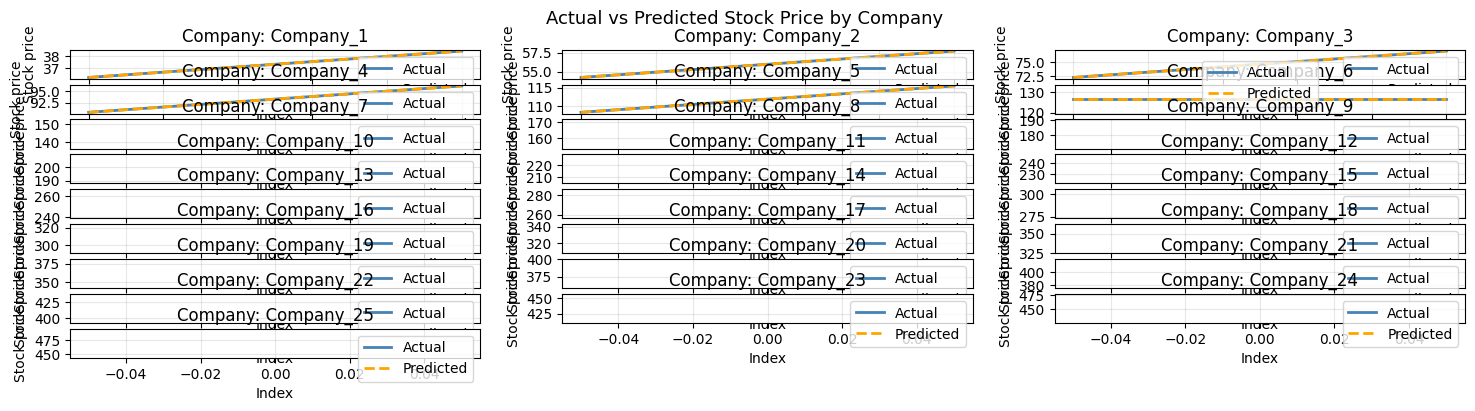

In [14]:
companies = df_pred["company_id"].unique()
n = len(companies)

fig, axes = plt.subplots(
    nrows=(1 if n <= 3 else (n + 2) // 3),
    ncols=min(n, 3),
    figsize=(6 * min(n, 3), 4),
    squeeze=False
)
axes_flat = axes.flatten()

for idx, company in enumerate(companies):
    ax = axes_flat[idx]
    sub = df_pred[df_pred["company_id"] == company].reset_index(drop=True)
    ax.plot(sub.index, sub["actual_price"],    label="Actual",    color="steelblue", linewidth=2)
    ax.plot(sub.index, sub["predicted_price"], label="Predicted", color="orange",   linewidth=2, linestyle="--")
    ax.set_title(f"Company: {company}")
    ax.set_xlabel("Index")
    ax.set_ylabel("Stock price")
    ax.legend()
    ax.grid(True, alpha=0.3)

for j in range(idx + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.suptitle("Actual vs Predicted Stock Price by Company", fontsize=13)
plt.tight_layout()
plt.savefig("stock_prediction.png", bbox_inches="tight", dpi=150)
plt.show()

# Get a list of unique company IDs from the DataFrame
companies = df_pred["company_id"].unique()

# Count how many companies we need to plot
n = len(companies)


# Create a grid of subplots:
# - Up to 3 columns per row
# - Rows are calculated dynamically based on number of companies
fig, axes = plt.subplots(
    nrows=(1 if n <= 3 else (n + 2) // 3),  # ensures enough rows
    ncols=min(n, 3),                        # max 3 columns
    figsize=(6 * min(n, 3), 4),             # scale width with columns
    squeeze=False                           # always return 2D array for consistency
)

# Flatten the 2D axes array into 1D for easy indexing
axes_flat = axes.flatten()


# Loop through each company and plot its data
for idx, company in enumerate(companies):
    
    # Select the subplot for this company
    ax = axes_flat[idx]
    
    # Filter data for the current company and reset index for clean plotting
    sub = df_pred[df_pred["company_id"] == company].reset_index(drop=True)
    
    # Plot actual stock prices
    ax.plot(
        sub.index,
        sub["actual_price"],
        label="Actual",
        color="steelblue",
        linewidth=2
    )
    
    # Plot predicted stock prices (dashed line for distinction)
    ax.plot(
        sub.index,
        sub["predicted_price"],
        label="Predicted",
        color="orange",
        linewidth=2,
        linestyle="--"
    )
    
    # Add title and axis labels
    ax.set_title(f"Company: {company}")
    ax.set_xlabel("Index")
    ax.set_ylabel("Stock price")
    
    # Show legend (Actual vs Predicted)
    ax.legend()
    
    # Add a light grid for readability
    ax.grid(True, alpha=0.3)


# Hide any unused subplots (if total grid > number of companies)
for j in range(idx + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)


# Add an overall title for the entire figure
plt.suptitle("Actual vs Predicted Stock Price by Company", fontsize=13)


# Adjust layout to prevent overlapping elements
plt.tight_layout()


# Save the figure as an image file
plt.savefig("stock_prediction.png", bbox_inches="tight", dpi=150)


# Display the plot in the notebook
plt.show()